## Aim

In this code, we use the .zar data from ECMWF and again look at the hourly reanalysis data for India. More specifically, we use the time chunked zar data as these are more efficient if we want to look at data over larger geographical areas instead of data for smaller geographical areas over longer time periods.

More specifically, these data can be found here:

https://cds.climate.copernicus.eu/datasets/reanalysis-era5-single-levels?tab=analysis_ready_data

These are the same data we have been using before (in the .nc) format: [ERA5 hourly data on single levels from 1940 to present](https://cds.climate.copernicus.eu/datasets/reanalysis-era5-single-levels?tab=overview). Instead of using the tab "Download" (which uses the .nc data), here the "Analysis Ready data" are used (in the .zarr format).

Herw we use the short time periods for a large area and use "time- chunked" data instead "geo-chunked" data that are used for long time periods for a limited area.



In [ ]:
!pip install -U "xarray" "zarr" "fsspec==2025.12.0" "aiohttp" --quiet

In [ ]:
import xarray as xr
import matplotlib.pyplot as plt

In [ ]:
# Time-chunked data for access optimised in spatial dimensions (e.g. for global maps)
# Surface
timechunked_sfc_url = "https://arco.datastores.ecmwf.int/cadl-arco-time-002/arco/reanalysis_era5_single_levels/sfc/timeChunked.zarr"

In [ ]:
import os
cdsapi_key = "fill in your CDS api key here"

In [ ]:
## Geo-chunked data for access along the time dimension (e.g. for time-series at a single point)
## surface_geo_url = "https://arco.datastores.ecmwf.int/cadl-arco-geo-002/arco/reanalysis_era5_single_levels/sfc/geoChunked.zarr"

In [ ]:
# Open one of the Zarr objects with xarray, the default example opens the geo-chunked surface variables
# From here:
ds = xr.open_zarr(
    timechunked_sfc_url,
    consolidated=True,
     storage_options = {
        "headers": {"Authorization": f"Bearer {cdsapi_key}"}
    }
)

# Inspect the variables
ds


<xarray.Dataset> Size: 63TB
Dimensions:    (time: 760992, latitude: 721, longitude: 1440)
Coordinates:
  * time       (time) datetime64[ns] 6MB 1940-01-01 ... 2026-10-23T23:00:00
  * latitude   (latitude) float64 6kB -90.0 -89.75 -89.5 ... 89.5 89.75 90.0
  * longitude  (longitude) float64 12kB -180.0 -179.8 -179.5 ... 179.5 179.8
Data variables: (12/20)
    blh        (time, latitude, longitude) float32 3TB dask.array<chunksize=(1, 721, 1024), meta=np.ndarray>
    cbh        (time, latitude, longitude) float32 3TB dask.array<chunksize=(1, 721, 1024), meta=np.ndarray>
    d2m        (time, latitude, longitude) float32 3TB dask.array<chunksize=(1, 721, 1024), meta=np.ndarray>
    fdir       (time, latitude, longitude) float32 3TB dask.array<chunksize=(1, 721, 1024), meta=np.ndarray>
    fg10       (time, latitude, longitude) float32 3TB dask.array<chunksize=(1, 721, 1024), meta=np.ndarray>
    msl        (time, latitude, longitude) float32 3TB dask.array<chunksize=(1, 721, 1024), meta=np.ndarray>
    ...         ...
    tcc        (time, latitude, longitude) float32 3TB dask.array<chunksize=(1, 721, 1024), meta=np.ndarray>
    tp         (time, latitude, longitude) float32 3TB dask.array<chunksize=(1, 721, 1024), meta=np.ndarray>
    u10        (time, latitude, longitude) float32 3TB dask.array<chunksize=(1, 721, 1024), meta=np.ndarray>
    u100       (time, latitude, longitude) float32 3TB dask.array<chunksize=(1, 721, 1024), meta=np.ndarray>
    v10        (time, latitude, longitude) float32 3TB dask.array<chunksize=(1, 721, 1024), meta=np.ndarray>
    v100       (time, latitude, longitude) float32 3TB dask.array<chunksize=(1, 721, 1024), meta=np.ndarray>
Attributes:
    Conventions:             CF-1.7
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_edition:            1
    GRIB_subCentre:          0
    history:                 2024-09-02T04:48 GRIB to CDM+CF via cfgrib-0.9.1...
    institution:             European Centre for Medium-Range Weather Forecasts

If you expand the "Data variables", we notice that we have 20 variables!! In order to have an idea what they mean, you use the follow code:

In [ ]:
for var in ds.data_vars:
    print(f"\nVariable: {var}")
    print(f"Description: {ds[var].attrs.get('long_name', 'Not available')}")
    print(f"Standard name: {ds[var].attrs.get('standard_name', 'Not available')}")
    print(f"Units: {ds[var].attrs.get('units', 'Not available')}")


Variable: blh
Description: Boundary layer height
Standard name: unknown
Units: m

Variable: cbh
Description: Cloud base height
Standard name: unknown
Units: m

Variable: d2m
Description: 2 metre dewpoint temperature
Standard name: unknown
Units: K

Variable: fdir
Description: Total sky direct solar radiation at surface
Standard name: unknown
Units: J m**-2

Variable: fg10
Description: 10 metre wind gust since previous post-processing
Standard name: unknown
Units: m s**-1

Variable: msl
Description: Mean sea level pressure
Standard name: air_pressure_at_mean_sea_level
Units: Pa

Variable: skt
Description: Skin temperature
Standard name: unknown
Units: K

Variable: slhf
Description: Surface latent heat flux
Standard name: surface_upward_latent_heat_flux
Units: J m**-2

Variable: sp
Description: Surface pressure
Standard name: surface_air_pressure
Units: Pa

Variable: sshf
Description: Surface sensible heat flux
Standard name: surface_upward_sensible_heat_flux
Units: J m**-2

Variable: s

In [ ]:
t2m = ds["t2m"]
t2m

<xarray.DataArray 't2m' (time: 760992, latitude: 721, longitude: 1440)> Size: 3TB
dask.array<open_dataset-t2m, shape=(760992, 721, 1440), dtype=float32, chunksize=(1, 721, 1024), chunktype=numpy.ndarray>
Coordinates:
  * time       (time) datetime64[ns] 6MB 1940-01-01 ... 2026-10-23T23:00:00
  * latitude   (latitude) float64 6kB -90.0 -89.75 -89.5 ... 89.5 89.75 90.0
  * longitude  (longitude) float64 12kB -180.0 -179.8 -179.5 ... 179.5 179.8
Attributes: (12/30)
    GRIB_NV:                                  0
    GRIB_Nx:                                  1440
    GRIB_Ny:                                  721
    GRIB_cfName:                              unknown
    GRIB_cfVarName:                           t2m
    GRIB_dataType:                            an
    ...                                       ...
    GRIB_totalNumber:                         0
    GRIB_typeOfLevel:                         surface
    GRIB_units:                               K
    long_name:                                2 metre temperature
    standard_name:                            unknown
    units:                                    K

We can learn a few things from the output. We see that the data is still big (2TB). This is the size of the data if we would fully download it!

In Zarr, we have chunks. We can see that one chunk is 2.82 MiB.  

We can use the following command for the dimension:

In [ ]:
t2m.shape

(760992, 721, 1440)

In [ ]:
t2m.encoding["chunks"]

(1, 721, 1024)

What this means is that each chunk has one time period and

In [ ]:
t2m.time

<xarray.DataArray 'time' (time: 760992)> Size: 6MB
array(['1940-01-01T00:00:00.000000000', '1940-01-01T01:00:00.000000000',
       '1940-01-01T02:00:00.000000000', ..., '2026-10-23T21:00:00.000000000',
       '2026-10-23T22:00:00.000000000', '2026-10-23T23:00:00.000000000'],
      dtype='datetime64[ns]')
Coordinates:
  * time     (time) datetime64[ns] 6MB 1940-01-01 ... 2026-10-23T23:00:00

How does the time variable look? It looks like these are hourly data. You can even expand this further:

The data is still big and over 2 TB. However, let us reduce this a little further and do a plot of one date only. Load will now load the data:

In [ ]:
%%time
t2_08_01_2025 = t2m.sel(time="2025-08-01T12:00").load()

CPU times: user 1.64 s, sys: 606 ms, total: 2.25 s
Wall time: 3.69 s


Let's plot this now but notice that the temperature is in Kelvin so we convert it to Celsius:

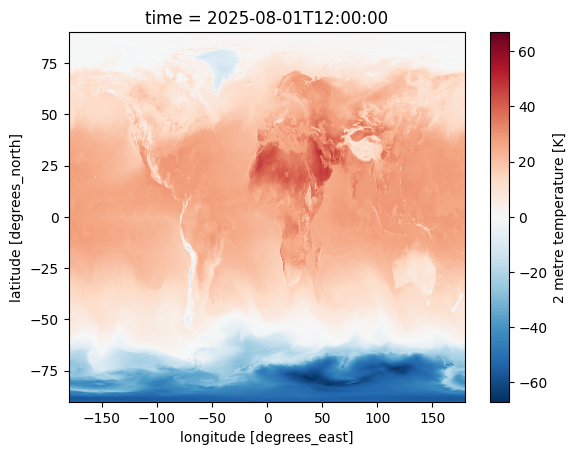

In [ ]:
t2_08_01_2025_C = t2_08_01_2025 - 273.15
t2_08_01_2025_C.plot()

Now make this plot a little nicer by adding a title, labels

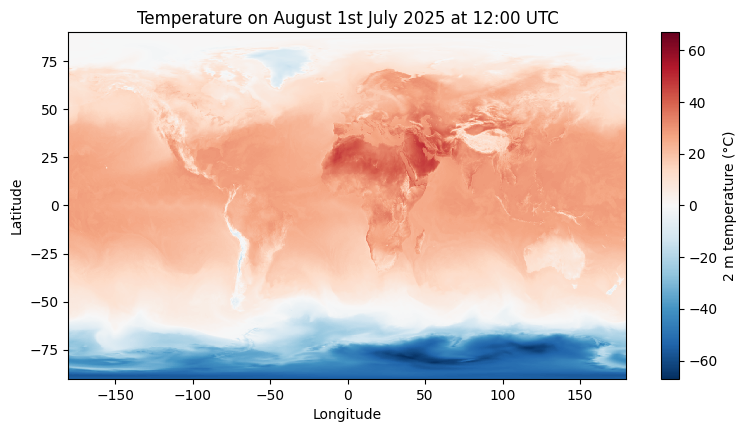

In [ ]:
t2_08_01_2025_C.plot(x="longitude", y="latitude",
    cmap="RdBu_r", center=0,
    figsize=(9, 4.5),
    cbar_kwargs={"label": "2 m temperature (°C)"},
)
plt.title("Temperature on August 1st July 2025 at 12:00 UTC")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.show()

You can also change the color map:

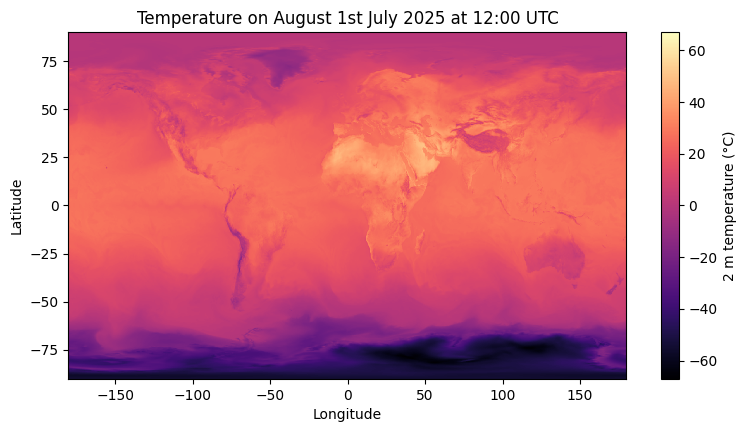

In [ ]:
t2_08_01_2025_C.plot(x="longitude", y="latitude",
    cmap="magma", center=0,
    figsize=(9, 4.5),
    cbar_kwargs={"label": "2 m temperature (°C)"},
)
plt.title("Temperature on August 1st July 2025 at 12:00 UTC")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.show()

Other things you can do is move the legend bar below, do a different projection etc. We will see!

Let's select now India only and this for the year 2025 only:

In [ ]:
ds

<xarray.Dataset> Size: 63TB
Dimensions:    (time: 760992, latitude: 721, longitude: 1440)
Coordinates:
  * time       (time) datetime64[ns] 6MB 1940-01-01 ... 2026-10-23T23:00:00
  * latitude   (latitude) float64 6kB -90.0 -89.75 -89.5 ... 89.5 89.75 90.0
  * longitude  (longitude) float64 12kB -180.0 -179.8 -179.5 ... 179.5 179.8
Data variables: (12/20)
    blh        (time, latitude, longitude) float32 3TB dask.array<chunksize=(1, 721, 1024), meta=np.ndarray>
    cbh        (time, latitude, longitude) float32 3TB dask.array<chunksize=(1, 721, 1024), meta=np.ndarray>
    d2m        (time, latitude, longitude) float32 3TB dask.array<chunksize=(1, 721, 1024), meta=np.ndarray>
    fdir       (time, latitude, longitude) float32 3TB dask.array<chunksize=(1, 721, 1024), meta=np.ndarray>
    fg10       (time, latitude, longitude) float32 3TB dask.array<chunksize=(1, 721, 1024), meta=np.ndarray>
    msl        (time, latitude, longitude) float32 3TB dask.array<chunksize=(1, 721, 1024), meta=np.ndarray>
    ...         ...
    tcc        (time, latitude, longitude) float32 3TB dask.array<chunksize=(1, 721, 1024), meta=np.ndarray>
    tp         (time, latitude, longitude) float32 3TB dask.array<chunksize=(1, 721, 1024), meta=np.ndarray>
    u10        (time, latitude, longitude) float32 3TB dask.array<chunksize=(1, 721, 1024), meta=np.ndarray>
    u100       (time, latitude, longitude) float32 3TB dask.array<chunksize=(1, 721, 1024), meta=np.ndarray>
    v10        (time, latitude, longitude) float32 3TB dask.array<chunksize=(1, 721, 1024), meta=np.ndarray>
    v100       (time, latitude, longitude) float32 3TB dask.array<chunksize=(1, 721, 1024), meta=np.ndarray>
Attributes:
    Conventions:             CF-1.7
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_edition:            1
    GRIB_subCentre:          0
    history:                 2024-09-02T04:48 GRIB to CDM+CF via cfgrib-0.9.1...
    institution:             European Centre for Medium-Range Weather Forecasts

In [ ]:
# Select t2m for 2025 and the approximate bounding box of India by chaining the commands:
t2m_india_2025 = (
    ds["t2m"]
    .sel(
        time=slice("2025-01-01", "2025-12-31"),
        latitude=slice(6, 37),
        longitude=slice(68, 98)
    )
)

t2m_india_2025

<xarray.DataArray 't2m' (time: 8760, latitude: 125, longitude: 121)> Size: 530MB
dask.array<getitem, shape=(8760, 125, 121), dtype=float32, chunksize=(1, 125, 89), chunktype=numpy.ndarray>
Coordinates:
  * time       (time) datetime64[ns] 70kB 2025-01-01 ... 2025-12-31T23:00:00
  * latitude   (latitude) float64 1kB 6.0 6.25 6.5 6.75 ... 36.5 36.75 37.0
  * longitude  (longitude) float64 968B 68.0 68.25 68.5 ... 97.5 97.75 98.0
Attributes: (12/30)
    GRIB_NV:                                  0
    GRIB_Nx:                                  1440
    GRIB_Ny:                                  721
    GRIB_cfName:                              unknown
    GRIB_cfVarName:                           t2m
    GRIB_dataType:                            an
    ...                                       ...
    GRIB_totalNumber:                         0
    GRIB_typeOfLevel:                         surface
    GRIB_units:                               K
    long_name:                                2 metre temperature
    standard_name:                            unknown
    units:                                    K

Select the first observation. Instead of slicing on a specific time and data, we use the "slicing by " method:

Please see [xarray on slicing](https://docs.xarray.dev/en/stable/user-guide/indexing.html) for the different slicing/subsetting methods in xarray.

In [ ]:
# This selects the very first hour of January 2025
t2m_india_2025_test = t2m_india_2025.isel(time=0).load()
t2m_india_2025_test

<xarray.DataArray 't2m' (latitude: 125, longitude: 121)> Size: 60kB
array([[299.1504 , 299.14258, 299.08398, ..., 300.88477, 300.6621 ,
        300.76758],
       [298.95508, 298.9707 , 299.00586, ..., 300.8125 , 300.59766,
        300.67383],
       [298.85156, 299.0879 , 299.1953 , ..., 300.76953, 300.54883,
        300.56445],
       ...,
       [279.35938, 277.73438, 277.05078, ..., 260.2246 , 261.30078,
        260.14062],
       [280.63086, 279.33398, 278.29883, ..., 262.50195, 264.06836,
        262.77148],
       [279.50195, 279.8203 , 280.05273, ..., 260.78125, 261.5078 ,
        260.32422]], dtype=float32)
Coordinates:
  * latitude   (latitude) float64 1kB 6.0 6.25 6.5 6.75 ... 36.5 36.75 37.0
  * longitude  (longitude) float64 968B 68.0 68.25 68.5 ... 97.5 97.75 98.0
    time       datetime64[ns] 8B 2025-01-01
Attributes: (12/30)
    GRIB_NV:                                  0
    GRIB_Nx:                                  1440
    GRIB_Ny:                                  721
    GRIB_cfName:                              unknown
    GRIB_cfVarName:                           t2m
    GRIB_dataType:                            an
    ...                                       ...
    GRIB_totalNumber:                         0
    GRIB_typeOfLevel:                         surface
    GRIB_units:                               K
    long_name:                                2 metre temperature
    standard_name:                            unknown
    units:                                    K

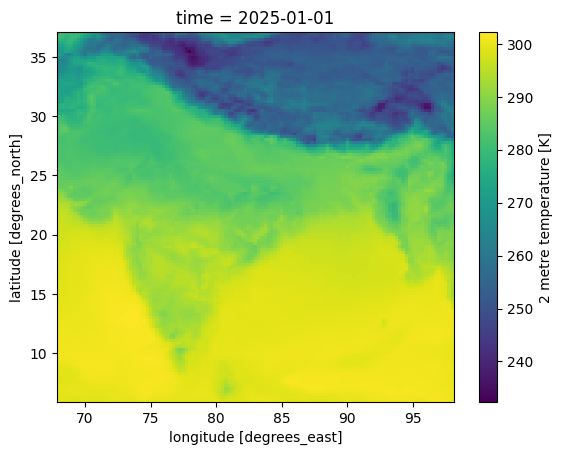

In [ ]:
t2m_india_2025_test.plot()

Select the entire day for September 2025:

In [ ]:
t2m_india_2025_sep_1 = t2m_india_2025.sel(
    time="2025-09-01"
)

Normally for our plotting, we can just proceed but when parallel computing is used with a framework called Dask (see later,  [tutorial](https://tutorial.xarray.dev/intermediate/xarray_and_dask.html)), we need to actually obtain the data (like in the form of a numpy array) in memory.

There are two ways we can download the data in memory. As a your result you get an xarray.DataArray with data stored as NumPy arrays.
1. [load()](https://docs.xarray.dev/en/v2025.03.1/generated/xarray.Dataset.load.html): Unlike compute(),  original dataset is modified and returned.
2. [compute()](): Loads data into memory from a disk or a remote source and a new data array is returned.It is also suggested to use rather compute() than load(). Here, the original data are not altered.

For more information, please see [here](https://tutorial.xarray.dev/intermediate/xarray_and_dask.html) among other sources.

In [ ]:
%%time
t2m_india_2025_sep_1_loaded = t2m_india_2025_sep_1.load()

CPU times: user 2.1 s, sys: 230 ms, total: 2.33 s
Wall time: 8.36 s


CPU time refers to the time on the CPU while the wall time is the "added time" due to network transfers e.g.

In [ ]:
print("Size (MB):", t2m_india_2025_sep_1_loaded.nbytes / 1e6)

Size (MB): 1.452


If we would load this a second time, we notice that this time it goes much faster so this delay would potentially have to do with the data transfer.

In [ ]:
%%time
t2m_india_2025_sep_1_loaded = t2m_india_2025_sep_1.load()

CPU times: user 213 µs, sys: 28 µs, total: 241 µs
Wall time: 246 µs


We can even save it to disk now:

This results in the hourly data for September 1 on 2025:

In [ ]:
t2m_india_2025_sep_1_loaded

<xarray.DataArray 't2m' (time: 24, latitude: 125, longitude: 121)> Size: 1MB
array([[[300.7011 , 300.5136 , 300.4433 , ..., 301.02338, 300.79486,
         300.6562 ],
        [300.3437 , 300.20697, 300.24017, ..., 301.07025, 300.92767,
         300.77728],
        [299.99408, 299.97455, 299.99017, ..., 301.42377, 301.2265 ,
         300.96478],
        ...,
        [288.07416, 289.86127, 288.97064, ..., 287.27142, 286.28314,
         285.3808 ],
        [292.83392, 292.96674, 291.9062 , ..., 286.414  , 285.33588,
         283.81635],
        [296.90424, 296.52728, 295.20892, ..., 283.77728, 282.623  ,
         281.64838]],

       [[300.82764, 300.61865, 300.54053, ..., 301.35693, 301.15967,
         301.0542 ],
        [300.46436, 300.31396, 300.38428, ..., 301.29834, 301.16162,
         301.03076],
        [300.271  , 300.23584, 300.27295, ..., 301.396  , 301.2378 ,
         301.07373],
...
        [285.92212, 287.70923, 286.65845, ..., 281.39087, 280.79712,
         280.0725 ],
        [290.98657, 290.72095, 289.36743, ..., 280.53735, 279.75806,
         279.47485],
        [295.62524, 293.0979 , 291.82056, ..., 278.9319 , 278.54907,
         279.50806]],

       [[300.85437, 300.6278 , 300.3661 , ..., 301.97156, 301.93054,
         301.94617],
        [300.74304, 300.5243 , 300.3036 , ..., 302.06335, 302.0028 ,
         301.96375],
        [300.65515, 300.5321 , 300.3368 , ..., 302.04578, 301.97546,
         301.94812],
        ...,
        [285.00867, 286.70398, 285.79968, ..., 281.1532 , 280.5829 ,
         280.02625],
        [289.8368 , 289.65125, 288.50085, ..., 280.42273, 279.66882,
         279.50085],
        [294.45398, 292.54382, 291.33484, ..., 278.61804, 278.32507,
         279.5829 ]]], dtype=float32)
Coordinates:
  * time       (time) datetime64[ns] 192B 2025-09-01 ... 2025-09-01T23:00:00
  * latitude   (latitude) float64 1kB 6.0 6.25 6.5 6.75 ... 36.5 36.75 37.0
  * longitude  (longitude) float64 968B 68.0 68.25 68.5 ... 97.5 97.75 98.0
Attributes: (12/30)
    GRIB_NV:                                  0
    GRIB_Nx:                                  1440
    GRIB_Ny:                                  721
    GRIB_cfName:                              unknown
    GRIB_cfVarName:                           t2m
    GRIB_dataType:                            an
    ...                                       ...
    GRIB_totalNumber:                         0
    GRIB_typeOfLevel:                         surface
    GRIB_units:                               K
    long_name:                                2 metre temperature
    standard_name:                            unknown
    units:                                    K

What was the mean temperature during September 1st in India?

In [ ]:
t2m_india_sep1_2025_mean = t2m_india_2025_sep_1.mean(dim="time").load()

In [ ]:
t2m_india_sep1_2025_mean

<xarray.DataArray 't2m' (latitude: 125, longitude: 121)> Size: 60kB
array([[300.53787, 300.58337, 300.63187, ..., 301.71585, 301.57523,
        301.50613],
       [300.52194, 300.56335, 300.62943, ..., 301.62747, 301.5255 ,
        301.43405],
       [300.56442, 300.60495, 300.66306, ..., 301.58875, 301.47644,
        301.387  ],
       ...,
       [294.4054 , 295.23596, 294.19714, ..., 288.6716 , 287.94373,
        286.5321 ],
       [298.87497, 298.824  , 297.36234, ..., 287.09036, 286.26096,
        285.4119 ],
       [300.7511 , 300.55344, 300.14163, ..., 285.8445 , 284.51468,
        283.9778 ]], dtype=float32)
Coordinates:
  * latitude   (latitude) float64 1kB 6.0 6.25 6.5 6.75 ... 36.5 36.75 37.0
  * longitude  (longitude) float64 968B 68.0 68.25 68.5 ... 97.5 97.75 98.0
Attributes: (12/30)
    GRIB_NV:                                  0
    GRIB_Nx:                                  1440
    GRIB_Ny:                                  721
    GRIB_cfName:                              unknown
    GRIB_cfVarName:                           t2m
    GRIB_dataType:                            an
    ...                                       ...
    GRIB_totalNumber:                         0
    GRIB_typeOfLevel:                         surface
    GRIB_units:                               K
    long_name:                                2 metre temperature
    standard_name:                            unknown
    units:                                    K

Convert this to Celcius:

In [ ]:
t2m_india_sep1_2025_mean_C = t2m_india_sep1_2025_mean - 273.15

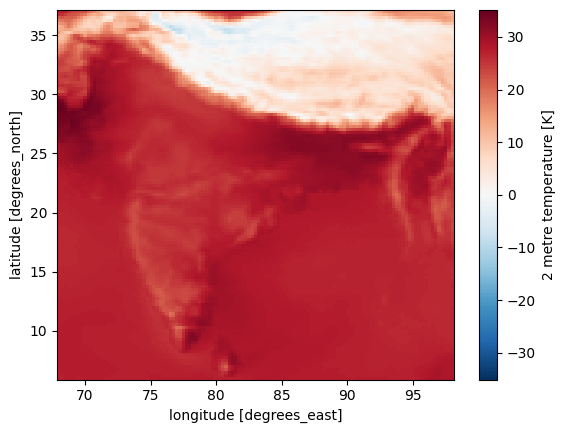

In [ ]:
t2m_india_sep1_2025_mean_C.plot()

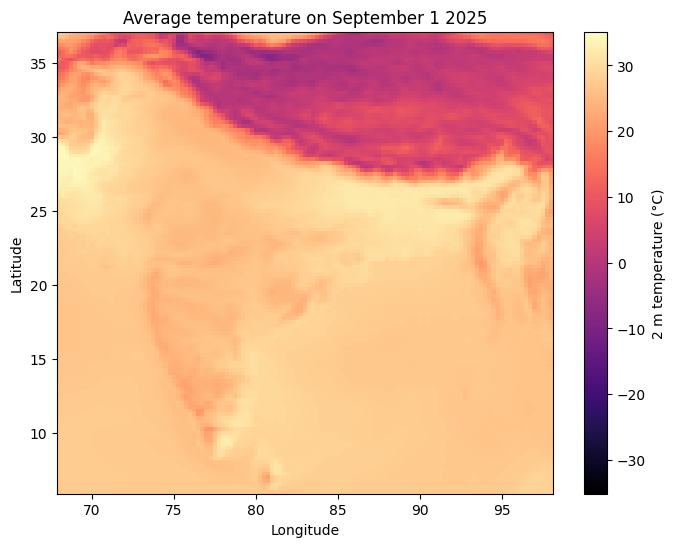

In [ ]:
t2m_india_sep1_2025_mean_C.plot(x="longitude", y="latitude",
    cmap="magma", center=0,
    figsize=(8, 6),
    cbar_kwargs={"label": "2 m temperature (°C)"},
)
plt.title("Average temperature on September 1 2025")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.show()

## Creating a giff for the hourly data for September 1st 2025

Please note that we can use the data array itself (and do not need to use the data for which we have used .compute() or load().

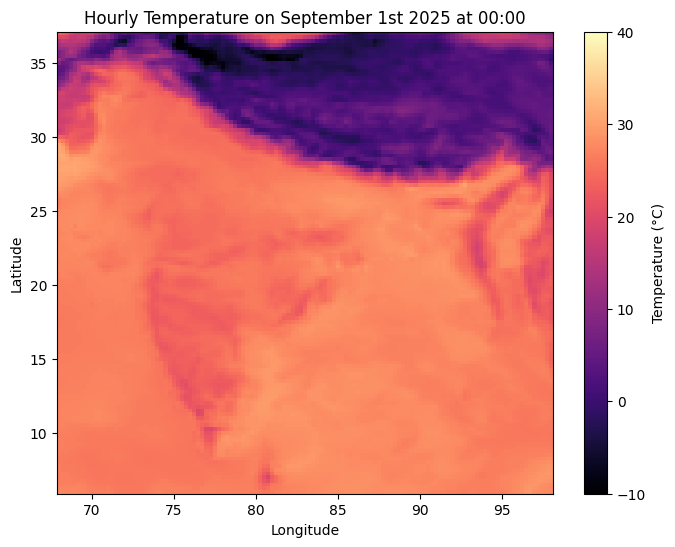

In [ ]:
## Code adapted from:
## https://colab.research.google.com/github/developmentseed/ingarss-workshop-2024/blob/main/book/docs/01_stac_and_zarr.ipynb
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

# Set up your figure
fig, ax = plt.subplots(figsize=(8, 6))

# Get the list of hours
t2m_india_2025_sep_1_C = t2m_india_2025_sep_1 - 273.15
hours = t2m_india_2025_sep_1_C.time.values
## hours - You will need that for the selection below

# Initialize with first image
data = t2m_india_2025_sep_1_C.isel(time=0)
img = ax.pcolormesh(
     data.longitude, data.latitude, data,
     cmap='magma', vmin=-10, vmax=40
 )
plt.colorbar(img, ax=ax, label='Temperature (°C)')
ax.set_title(f'Daily hourly Temperature on {str(hours[0])[12:]}')
ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')

# # Update function with each frame/image
def update(frame):
    ax.clear()
    data = t2m_india_2025_sep_1_C.isel(time=frame)
    img = ax.pcolormesh(
        data.longitude, data.latitude, data,
        cmap='magma', vmin=-10, vmax=40
    )
    ax.set_title(f'Hourly Temperature on September 1st 2025 at {str(hours[frame])[11:16]}')
    ax.set_xlabel('Longitude')
    ax.set_ylabel('Latitude')
    return img,

# Create the animation
anim = FuncAnimation(
    fig, update, frames=len(hours),
    interval=200, blit=False
)

# Display the animation
HTML(anim.to_jshtml())

# Uncomment this line if you want to save the animation
# anim.save(
#     "india_temperature_2025-09-01.gif",
#     writer="pillow",
#     fps=5
# )

Now you can download the .gif to your local computer (if you are working in Google Colab).

**Now it is your turn!**

1. The daily and hourly and yearly dataset is just one dataset of the ECMWF. The CDS has many datasets some are only for the land (land-ERA5), some have already monthly observations, etc.  
2. Use another latitude and longitude and try something on an area of your interest.
3. One dataset (see above) has many other variables other than temperature. Can you try something with another variable such as wind, precipitation, sea surface temperature, etc? You can use the steps above or any of the references in the references list below.

## References

https://tutorial.xarray.dev/intermediate/intro-to-zarr.html

https://github.com/developmentseed/ingarss-workshop-2024

https://colab.research.google.com/github/developmentseed/ingarss-workshop-2024/blob/main/book/docs/01_stac_and_zarr.ipynb

https://github.com/thriveGEO/cng-101-workshop-2026/blob/main/22_intro_zarr.ipynb

https://docs.xarray.dev/en/v2025.09.0/user-guide/dask.html

https://docs.xarray.dev/en/v2025.09.0/user-guide/dask.html